---
# **Project Details**

**Author**: Sai Gavaskar Sakalam

**Date**:  March 18, 2026

**Program**: UT Austin – Post Graduate Program in Artificial Intelligence & Machine Learning

**Project**: FoodHub Data Analysis

---

# FoodHub – Food Delivery Order Analysis

### Context

FoodHub is a food delivery app in New York. Customers order from many restaurants through one app. A delivery person picks up the food from the restaurant and takes it to the customer, and the customer can rate the order. FoodHub earns a fixed commission from the restaurant on every order.

### Objective

Analyse about 1,900 orders to understand demand for different restaurants and cuisines, customer ratings, and food preparation and delivery times. Then give recommendations to improve the customer experience and grow the business.

### Data Dictionary

* order_id: Unique ID of the order
* customer_id: ID of the customer who ordered the food
* restaurant_name: Name of the restaurant
* cuisine_type: Cuisine ordered by the customer
* cost_of_the_order: Cost of the order
* day_of_the_week: Indicates whether the order is placed on a weekday or weekend (The weekday is from Monday to Friday and the weekend is Saturday and Sunday)
* rating: Rating given by the customer out of 5
* food_preparation_time: Time (in minutes) taken by the restaurant to prepare the food. This is calculated by taking the difference between the timestamps of the restaurant's order confirmation and the delivery person's pick-up confirmation.
* delivery_time: Time (in minutes) taken by the delivery person to deliver the food package. This is calculated by taking the difference between the timestamps of the delivery person's pick-up confirmation and drop-off information

### Importing libraries

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 -q --user

**Note:** after the install cell finishes, restart the runtime (Colab) or kernel (Jupyter), then run the rest of the notebook from the next cell.

In [2]:
# import libraries for data manipulation
import numpy as np
import pandas as pd

# import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

### Understanding the structure of the data

In [8]:
# Data files are kept in the local data/ folder.
# On Google Colab: mount Drive and point the paths below to your Drive folder.

In [9]:
# read the data (files are kept in the local data/ folder)
foodhub_df = pd.read_csv('data/foodhub_order.csv')

In [11]:
# view the first 5 rows
foodhub_df.head(5)

,order_id,customer_id,restaurant_name,cuisine_type,cost_of_the_order,day_of_the_week,rating,food_preparation_time,delivery_time
0,1477147,337525,Hangawi,Korean,30.75,Weekend,Not given,25,20
1,1477685,358141,Blue Ribbon Sushi Izakaya,Japanese,12.08,Weekend,Not given,25,23
2,1477070,66393,Cafe Habana,Mexican,12.23,Weekday,5,23,28
3,1477334,106968,Blue Ribbon Fried Chicken,American,29.20,Weekend,3,25,15
4,1478249,76942,Dirty Bird to Go,American,11.59,Weekday,4,25,24


### Data shape (rows and columns)

In [14]:
# Get the number of rows and columns using the DataFrame's .shape attribute.
rows, columns = foodhub_df.shape

# Print the number of rows and columns, using comma formatting for better readability.
#
print(f'Number of Rows   : {rows:,}')
print(f'Number of Columns: {columns:,}')

Number of Rows   : 1,898
Number of Columns: 9


#### Observations:
* The dataset contains **1,898 rows** and **9 columns**.


### Data types of the columns

In [16]:
# Use .info() to get a concise summary of the DataFrame, including the data types of each column and non-null values.
foodhub_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1898 entries, 0 to 1897
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               1898 non-null   int64  
 1   customer_id            1898 non-null   int64  
 2   restaurant_name        1898 non-null   object 
 3   cuisine_type           1898 non-null   object 
 4   cost_of_the_order      1898 non-null   float64
 5   day_of_the_week        1898 non-null   object 
 6   rating                 1898 non-null   object 
 7   food_preparation_time  1898 non-null   int64  
 8   delivery_time          1898 non-null   int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 133.6+ KB


#### Observations:
Upon inspecting the `foodhub_df` using `.info()`, several key insights about the dataset's structure and quality emerge, setting the stage for robust analysis:

*   **Dataset Dimensions**: The DataFrame comprises **1,898 entries (rows)**, meticulously indexed from 0 to 1897, and contains **9 distinct columns**, providing a comprehensive view of individual food orders.

*   **Data Completeness (No Missing Values)**: A remarkable finding is that **all 9 columns exhibit 1,898 non-null entries**, matching the total number of rows. This signifies a perfectly complete dataset with **no missing values** across any feature. This pristine state significantly streamlines the data preprocessing phase, allowing us to focus immediately on analysis rather than imputation.

*   **Data Type Distribution**: The columns are categorized into three distinct data types, each serving a specific purpose:
    *   **Integer (`int64`)**: Four columns (`order_id`, `customer_id`, `food_preparation_time`, `delivery_time`) are stored as integers, ideal for unique identifiers and precise time measurements.
    *   **Object (`object`)**: Four columns (`restaurant_name`, `cuisine_type`, `day_of_the_week`, `rating`) are identified as 'object' types, indicating they primarily contain string or mixed data. These often represent categorical information.
    *   **Float (`float64`)**: One column (`cost_of_the_order`) is a float, perfectly suited for representing continuous numerical values, such as monetary costs.

*   **Critical `rating` Column Insight**: The `rating` column, while crucial for customer feedback analysis, is currently an `object` type. A prior peek at `foodhub_df.head()` revealed entries like 'Not given', confirming the presence of non-numeric values. This necessitates a strategic preprocessing step: converting 'Not given' to a null-equivalent (e.g., `np.nan`) and then casting the column to a numeric type (e.g., `float`) to enable quantitative analysis. This transformation will be vital for understanding customer satisfaction.

*   **Memory Footprint**: The DataFrame maintains an efficient memory usage of approximately **133.6+ KB**. This compact size ensures swift processing and handling, even as we dive deeper into complex analyses.

In summary, the `foodhub_df` presents a clean and well-structured foundation for our analysis, with the primary immediate task being the careful handling of the `rating` column to unlock its analytical potential.

#### Observations:


### Missing values

In [18]:
# Check for missing values in each column
missing_values = foodhub_df.isnull().sum()

# Print the number of missing values per column
print("Number of missing values per column:")
print(missing_values)

# Check if there are any missing values in the entire DataFrame
total_missing = foodhub_df.isnull().sum().sum()
if total_missing == 0:
    print("\nThere are no missing values in the dataset.")
else:
    print(f"\nThere are a total of {total_missing} missing values in the dataset.")

Number of missing values per column:
order_id                 0
customer_id              0
restaurant_name          0
cuisine_type             0
cost_of_the_order        0
day_of_the_week          0
rating                   0
food_preparation_time    0
delivery_time            0
dtype: int64

There are no missing values in the dataset.


#### Observations:
1.  Upon checking, it is confirmed that there are **no missing values** in any of the columns in the `foodhub_df` dataset.
2.  Therefore, no treatment for missing values is required for this dataset.

### Statistical summary and food preparation time

In [19]:
# Replace 'Not given' in 'rating' with np.nan to treat them as missing values
foodhub_df['rating'] = foodhub_df['rating'].replace('Not given', np.nan)

# Convert the 'rating' column to numeric type (float) for statistical analysis
foodhub_df['rating'] = pd.to_numeric(foodhub_df['rating'])

# Get the statistical summary of the data
print("Statistical Summary of the DataFrame:")
display(foodhub_df.describe())

# Get the minimum, average, and maximum food preparation time
min_prep_time = foodhub_df['food_preparation_time'].min()
avg_prep_time = foodhub_df['food_preparation_time'].mean()
max_prep_time = foodhub_df['food_preparation_time'].max()

print(f"\nMinimum food preparation time: {min_prep_time} minutes")
print(f"Average food preparation time: {avg_prep_time:.2f} minutes")
print(f"Maximum food preparation time: {max_prep_time} minutes")

Statistical Summary of the DataFrame:


,order_id,customer_id,cost_of_the_order,rating,food_preparation_time,delivery_time
count,1.898000e+03,1898.000000,1898.000000,1162.000000,1898.000000,1898.000000
mean,1.477496e+06,171168.478398,16.498851,4.344234,27.371970,24.161749
std,5.480497e+02,113698.139743,7.483812,0.741478,4.632481,4.972637
min,1.476547e+06,1311.000000,4.470000,3.000000,20.000000,15.000000
25%,1.477021e+06,77787.750000,12.080000,4.000000,23.000000,20.000000
50%,1.477496e+06,128600.000000,14.140000,5.000000,27.000000,25.000000
75%,1.477970e+06,270525.000000,22.297500,5.000000,31.000000,28.000000
max,1.478444e+06,405334.000000,35.410000,5.000000,35.000000,33.000000



Minimum food preparation time: 20 minutes
Average food preparation time: 27.37 minutes
Maximum food preparation time: 35 minutes


#### Observations:
*   The statistical summary above now includes the 'rating' column as a numeric type, allowing for meaningful calculations.
*   Minimum food preparation time: This indicates the quickest an order has been prepared.
*   Average food preparation time: This gives a central tendency of how long it generally takes for food to be prepared.
*   Maximum food preparation time: This highlights the longest preparation time recorded, which could be an outlier or indicate complex orders.

### Orders without a rating

In [21]:
# Calculate the number of orders where the rating is NaN (Not given)
unrated_orders = foodhub_df['rating'].isnull().sum()

# Print the result
print(f'Number of orders not rated: {unrated_orders:,}')

Number of orders not rated: 736


#### Observations:
*   There are **736 orders** in the dataset that do not have a customer rating. This represents a significant portion of the total orders where customer feedback is missing, which could impact comprehensive customer satisfaction analysis.

### Exploratory Data Analysis (EDA)

### Univariate Analysis

### Distribution of each variable

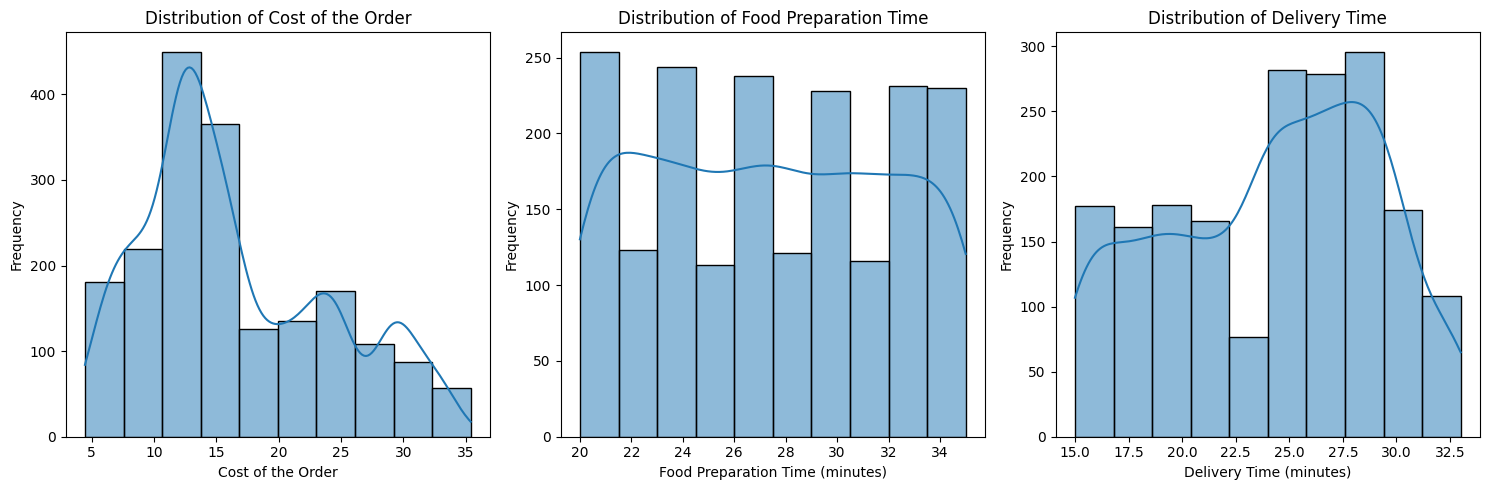

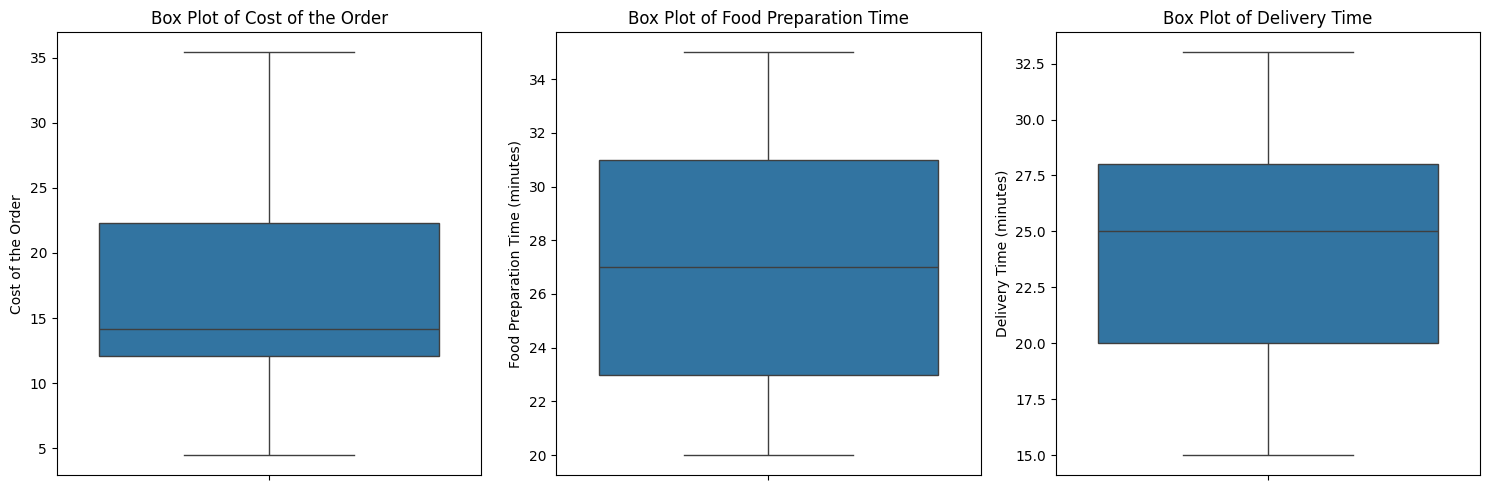

In [22]:
# Explore numerical variables: cost_of_the_order, food_preparation_time, delivery_time

plt.figure(figsize=(15, 5))

# Histogram for cost_of_the_order
plt.subplot(1, 3, 1) # 1 row, 3 columns, 1st plot
sns.histplot(foodhub_df['cost_of_the_order'], kde=True, bins=10)
plt.title('Distribution of Cost of the Order')
plt.xlabel('Cost of the Order')
plt.ylabel('Frequency')

# Histogram for food_preparation_time
plt.subplot(1, 3, 2) # 1 row, 3 columns, 2nd plot
sns.histplot(foodhub_df['food_preparation_time'], kde=True, bins=10)
plt.title('Distribution of Food Preparation Time')
plt.xlabel('Food Preparation Time (minutes)')
plt.ylabel('Frequency')

# Histogram for delivery_time
plt.subplot(1, 3, 3) # 1 row, 3 columns, 3rd plot
sns.histplot(foodhub_df['delivery_time'], kde=True, bins=10)
plt.title('Distribution of Delivery Time')
plt.xlabel('Delivery Time (minutes)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()


plt.figure(figsize=(15, 5))

# Boxplot for cost_of_the_order
plt.subplot(1, 3, 1) # 1 row, 3 columns, 1st plot
sns.boxplot(y=foodhub_df['cost_of_the_order'])
plt.title('Box Plot of Cost of the Order')
plt.ylabel('Cost of the Order')

# Boxplot for food_preparation_time
plt.subplot(1, 3, 2) # 1 row, 3 columns, 2nd plot
sns.boxplot(y=foodhub_df['food_preparation_time'])
plt.title('Box Plot of Food Preparation Time')
plt.ylabel('Food Preparation Time (minutes)')

# Boxplot for delivery_time
plt.subplot(1, 3, 3) # 1 row, 3 columns, 3rd plot
sns.boxplot(y=foodhub_df['delivery_time'])
plt.title('Box Plot of Delivery Time')
plt.ylabel('Delivery Time (minutes)')

plt.tight_layout()
plt.show()

#### Observations for Numerical Variables:

**1. Cost of the Order (`cost_of_the_order`)**:
*   **Histogram**: The distribution of order costs appears to be right-skewed, with a higher frequency of lower-cost orders. There's a peak around \$10-\$15, and the frequency gradually decreases as the cost increases. This suggests that most customers place relatively smaller orders.
*   **Boxplot**: The boxplot confirms the right-skewness and shows a range of order costs. There are no clear outliers visible, indicating that while some orders are more expensive, they are within a reasonable range for the dataset.

**2. Food Preparation Time (`food_preparation_time`)**:
*   **Histogram**: The distribution of food preparation time seems to be relatively uniform or slightly bimodal, with peaks at different preparation times (e.g., around 25 minutes and 30 minutes). The times range from 20 to 35 minutes, indicating a controlled process within restaurants.
*   **Boxplot**: The boxplot shows a fairly symmetrical distribution around the median, with no significant outliers. The spread is also relatively narrow, suggesting consistency in preparation times across different orders.

**3. Delivery Time (`delivery_time`)**:
*   **Histogram**: The delivery time distribution appears somewhat normal or slightly left-skewed, with a central tendency around 25 minutes. Most deliveries fall within a concentrated range, with fewer very short or very long delivery times.
*   **Boxplot**: The boxplot confirms a symmetrical distribution with the median close to the center of the box. Similar to food preparation time, there are no extreme outliers, indicating generally consistent delivery times.

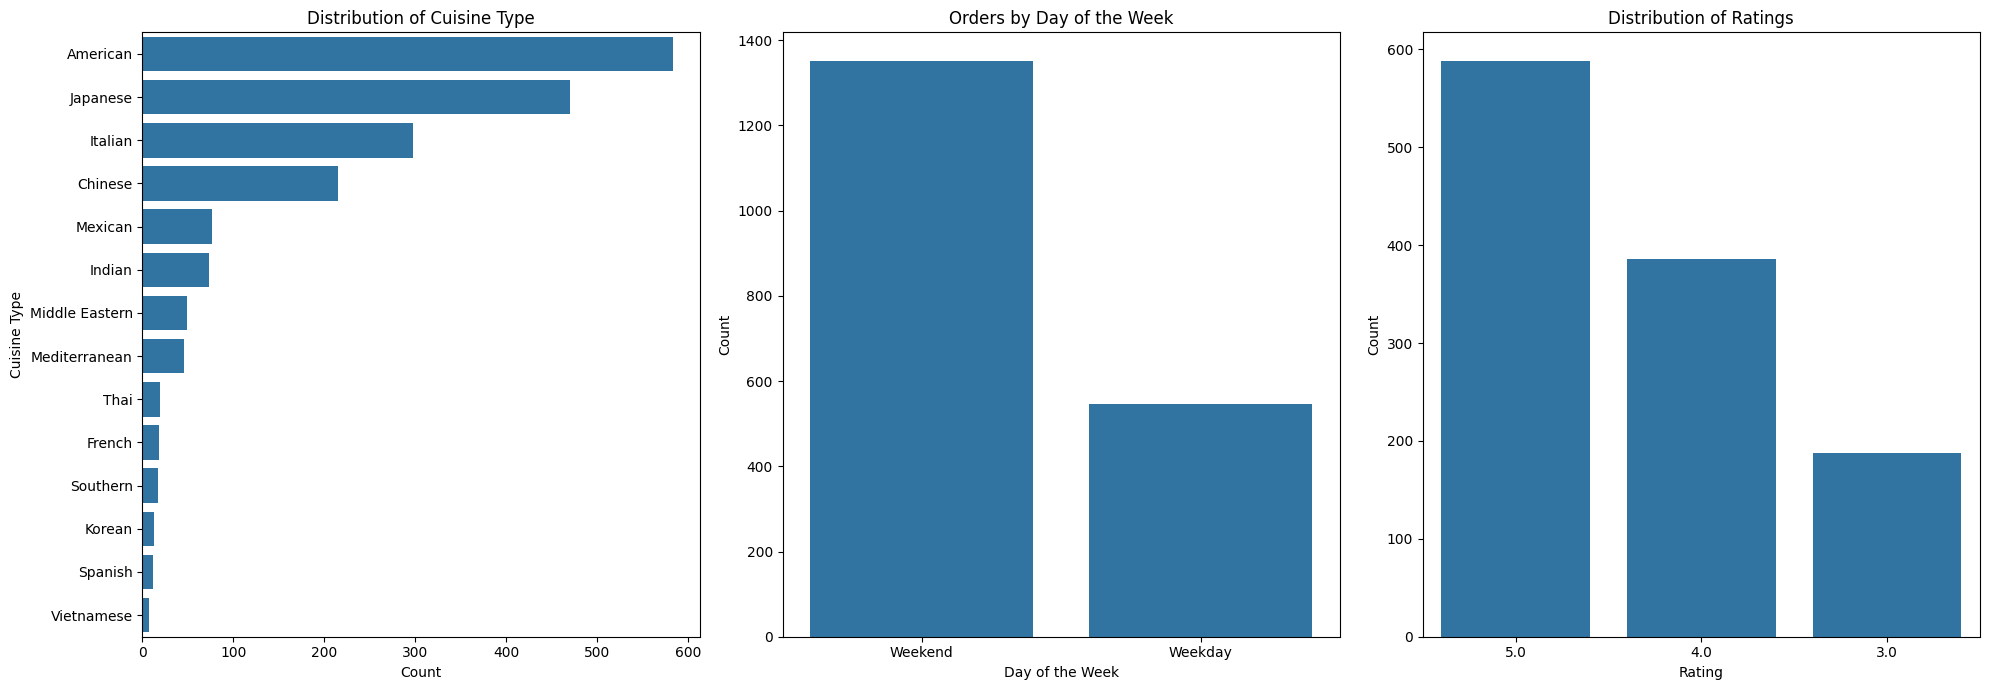

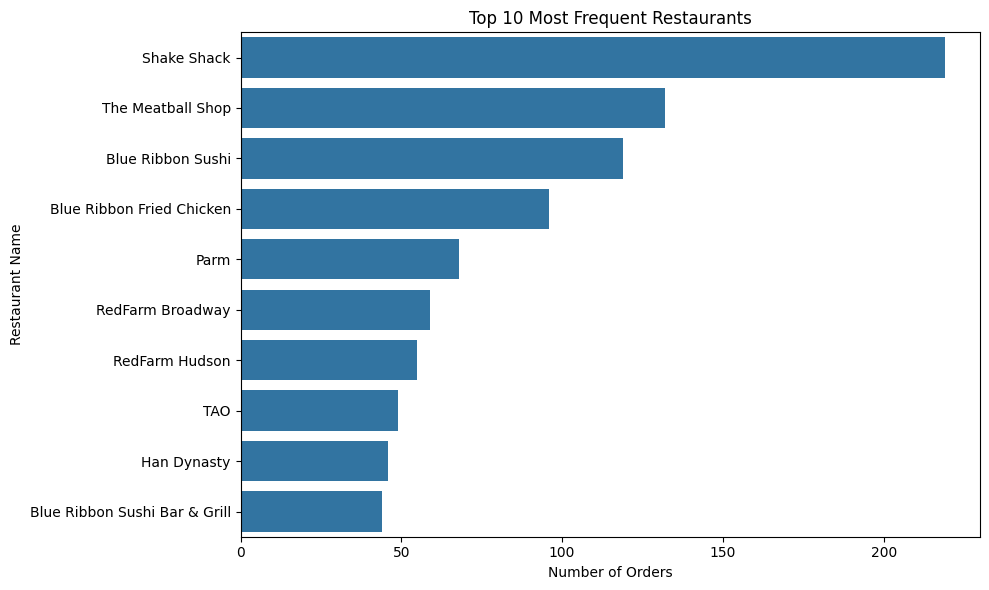

In [23]:
# Explore categorical variables: restaurant_name, cuisine_type, day_of_the_week, rating

plt.figure(figsize=(20, 7))
# Countplot for cuisine_type
plt.subplot(1, 3, 1) # 1 row, 3 columns, 1st plot
sns.countplot(data=foodhub_df, y='cuisine_type', order = foodhub_df['cuisine_type'].value_counts().index)
plt.title('Distribution of Cuisine Type')
plt.xlabel('Count')
plt.ylabel('Cuisine Type')

# Countplot for day_of_the_week
plt.subplot(1, 3, 2) # 1 row, 3 columns, 2nd plot
sns.countplot(data=foodhub_df, x='day_of_the_week', order = foodhub_df['day_of_the_week'].value_counts().index)
plt.title('Orders by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Count')

# Countplot for rating
plt.subplot(1, 3, 3) # 1 row, 3 columns, 3rd plot
sns.countplot(data=foodhub_df, x='rating', order = foodhub_df['rating'].value_counts().index)
plt.title('Distribution of Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

# For restaurant_name, it's better to show top N as there are too many unique restaurants
plt.figure(figsize=(10, 6))
top_10_restaurants = foodhub_df['restaurant_name'].value_counts().head(10)
sns.barplot(x=top_10_restaurants.values, y=top_10_restaurants.index)
plt.title('Top 10 Most Frequent Restaurants')
plt.xlabel('Number of Orders')
plt.ylabel('Restaurant Name')
plt.tight_layout()
plt.show()

#### Observations:

**1. Cuisine Type (`cuisine_type`)**:
*   The most popular cuisine types appear to be American, Japanese, and Italian, with American cuisine having the highest number of orders.
*   There's a long tail of less frequent cuisine types, indicating a wide variety of options available through FoodHub, but with clear preferences among customers.

**2. Day of the Week (`day_of_the_week`)**:
*   Orders are significantly higher on weekends (Saturday and Sunday) compared to weekdays. This suggests that customers are more likely to use the food delivery service during their days off.
*   Among weekdays, the order counts are relatively consistent.

**3. Rating (`rating`)**:
*   A substantial portion of orders (`736` as found in the missing ratings check) remain unrated (`NaN`).
*   Among the rated orders, ratings of 5 and 4 are the most frequent, indicating generally high customer satisfaction for those who do provide feedback.
*   Ratings of 3, 2, and 1 are less common, which is positive for the company's service reputation.

**4. Restaurant Name (`restaurant_name`)**:
*   The bar plot clearly shows that a few restaurants receive a disproportionately high number of orders. For example, 'Shake Shack' and 'The Meatball Shop' are among the most frequently ordered from establishments.
*   This highlights the popularity and potential market dominance of certain restaurants within the FoodHub platform.

### Most popular cuisine on weekends

In [24]:
# Filter the DataFrame for weekend orders
weekend_orders = foodhub_df[foodhub_df['day_of_the_week'] == 'Weekend']

# Count the occurrences of each cuisine type on weekends
popular_cuisine_weekend = weekend_orders['cuisine_type'].value_counts().idxmax()

# Print the most popular cuisine on weekends
print(f'The most popular cuisine on weekends is: {popular_cuisine_weekend}')

The most popular cuisine on weekends is: American


#### Observations:
*   The most popular cuisine type on weekends is **American**. This suggests a strong preference among customers for American dishes during their days off.

### Share of orders costing more than $20

In [25]:
# Calculate the number of orders costing more than 20 dollars
orders_gt_20 = foodhub_df[foodhub_df['cost_of_the_order'] > 20].shape[0]

# Calculate the total number of orders
total_orders = foodhub_df.shape[0]

# Calculate the percentage
percentage_gt_20 = (orders_gt_20 / total_orders) * 100

# Print the result
print(f'{percentage_gt_20:.2f}% of the orders cost more than 20 dollars.')

29.24% of the orders cost more than 20 dollars.


#### Observations:
*   **29.24%** of the orders cost more than 20 dollars. This indicates that nearly one-third of the orders contribute a higher revenue per order.

### Mean delivery time

In [26]:
# Calculate the mean order delivery time
mean_delivery_time = foodhub_df['delivery_time'].mean()

# Print the result
print(f'The mean order delivery time is: {mean_delivery_time:.2f} minutes')

The mean order delivery time is: 24.16 minutes


#### Observations:
*   The mean order delivery time is **24.16 minutes**.

### Top 3 most frequent customers

The top 3 customers are selected for 20% discount vouchers.

In [27]:
# Find the top 3 most frequent customers
top_3_customers = foodhub_df['customer_id'].value_counts().head(3)

# Print the result
print("Top 3 Most Frequent Customers and their Order Counts:")
for customer_id, order_count in top_3_customers.items():
    print(f"Customer ID: {customer_id}, Orders Placed: {order_count}")

Top 3 Most Frequent Customers and their Order Counts:
Customer ID: 52832, Orders Placed: 13
Customer ID: 47440, Orders Placed: 10
Customer ID: 83287, Orders Placed: 9


#### Observations:


#### Observations:
*   The top 3 most frequent customers have been identified:
    *   **Customer ID: 52832** placed **13 orders**
    *   **Customer ID: 47440** placed **10 orders**
    *   **Customer ID: 83287** placed **9 orders**

These customers will be eligible for the 20% discount vouchers.

### Multivariate Analysis

### Multivariate analysis: relationships between variables

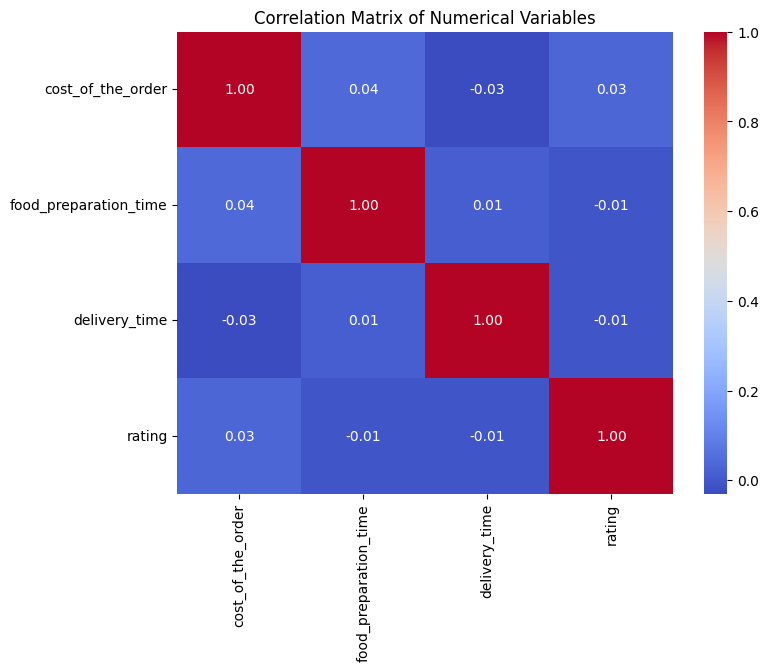

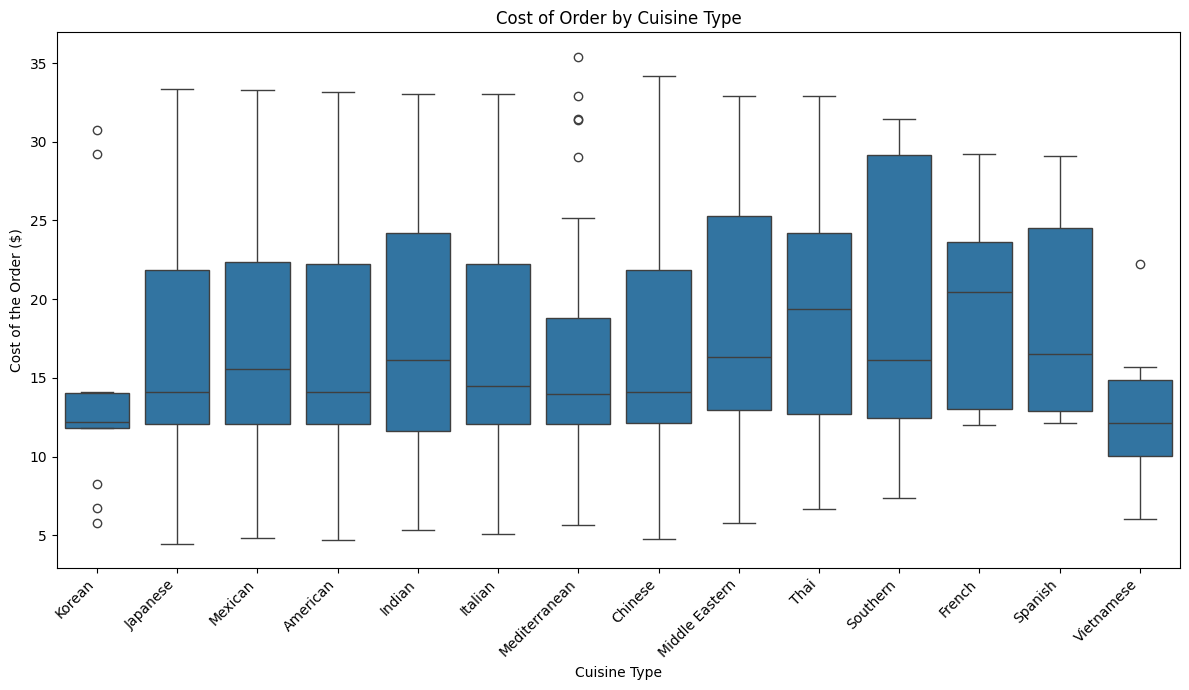

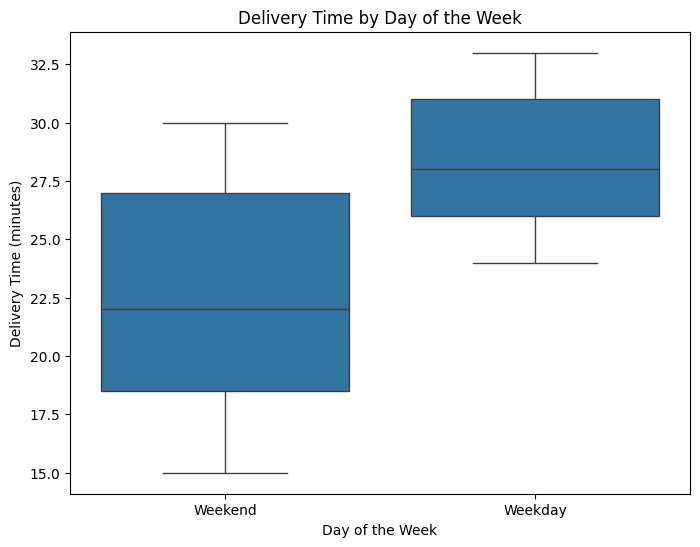

/tmp/ipykernel_173/2067197497.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='rating', y='food_preparation_time', data=avg_times_by_rating, palette='viridis')
/tmp/ipykernel_173/2067197497.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='rating', y='delivery_time', data=avg_times_by_rating, palette='magma')


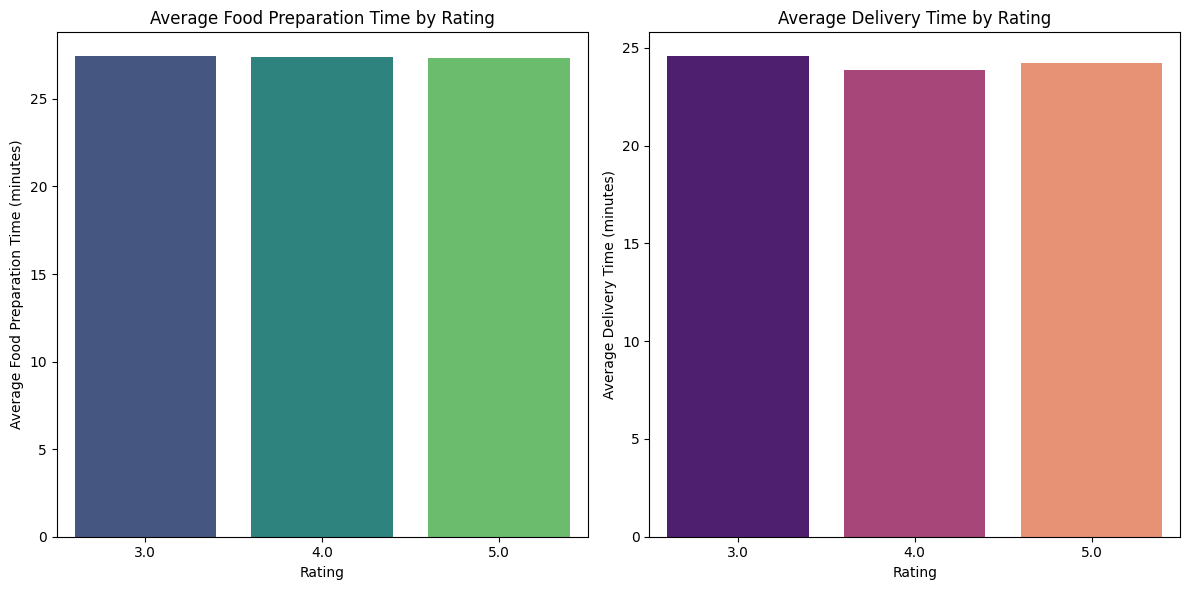

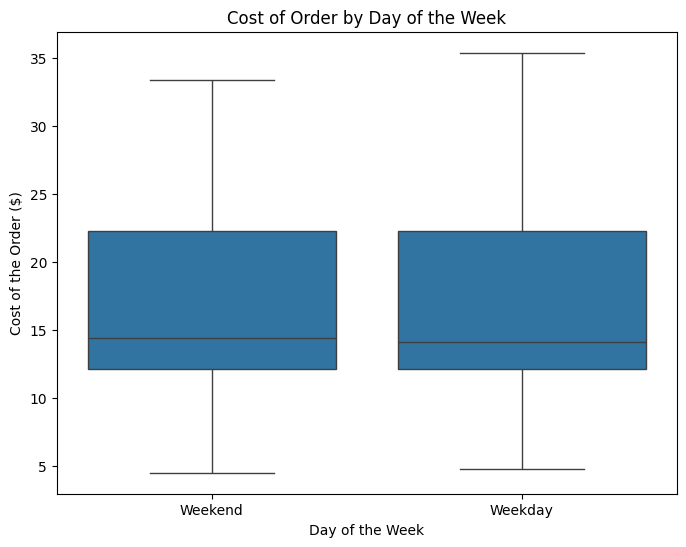

In [28]:
# 1. Correlation Matrix for Numerical Variables
plt.figure(figsize=(8, 6))
sns.heatmap(foodhub_df[['cost_of_the_order', 'food_preparation_time', 'delivery_time', 'rating']].corr(),
            annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Numerical Variables')
plt.show()

# 2. Relationship between Cost of Order and Cuisine Type
plt.figure(figsize=(12, 7))
sns.boxplot(x='cuisine_type', y='cost_of_the_order', data=foodhub_df)
plt.title('Cost of Order by Cuisine Type')
plt.xlabel('Cuisine Type')
plt.ylabel('Cost of the Order ($)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 3. Relationship between Delivery Time and Day of the Week
plt.figure(figsize=(8, 6))
sns.boxplot(x='day_of_the_week', y='delivery_time', data=foodhub_df)
plt.title('Delivery Time by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Delivery Time (minutes)')
plt.show()

# 4. Relationship between Rating, Food Preparation Time, and Delivery Time
# Group by rating and calculate mean food_preparation_time and delivery_time
# This is done for rated orders only
rated_orders_df = foodhub_df.dropna(subset=['rating'])
avg_times_by_rating = rated_orders_df.groupby('rating')[['food_preparation_time', 'delivery_time']].mean().reset_index()

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
sns.barplot(x='rating', y='food_preparation_time', data=avg_times_by_rating, palette='viridis')
plt.title('Average Food Preparation Time by Rating')
plt.xlabel('Rating')
plt.ylabel('Average Food Preparation Time (minutes)')

plt.subplot(1, 2, 2)
sns.barplot(x='rating', y='delivery_time', data=avg_times_by_rating, palette='magma')
plt.title('Average Delivery Time by Rating')
plt.xlabel('Rating')
plt.ylabel('Average Delivery Time (minutes)')

plt.tight_layout()
plt.show()

# 5. Relationship between Cost of Order and Day of the Week
plt.figure(figsize=(8, 6))
sns.boxplot(x='day_of_the_week', y='cost_of_the_order', data=foodhub_df)
plt.title('Cost of Order by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Cost of the Order ($)')
plt.show()

#### Observations for Multivariate Analysis:

**1. Correlation Matrix of Numerical Variables:**
*   There appears to be no strong linear correlation between `cost_of_the_order`, `food_preparation_time`, `delivery_time`, and `rating`. This suggests that these numerical variables are largely independent of each other.

**2. Cost of Order by Cuisine Type:**
*   The boxplot indicates that the `cost_of_the_order` varies across different `cuisine_type`s. Some cuisines, like 'Korean' and 'Japanese', show a wider range of order costs and potentially higher median costs, while others like 'American' have a broad distribution. 'French' cuisine appears to have some of the highest maximum order costs.

**3. Delivery Time by Day of the Week:**
*   The delivery time distribution is relatively consistent between 'Weekday' and 'Weekend', though 'Weekend' might show a slightly wider spread or slightly higher median delivery times, which could be attributed to increased order volume. Overall, delivery times seem well-managed on both types of days.

**4. Average Food Preparation Time and Delivery Time by Rating:**
*   There's no clear linear trend between `rating` and average `food_preparation_time` or `delivery_time`. Orders receiving a rating of 5, 4, or 3 have very similar average preparation and delivery times. This suggests that variations in preparation or delivery times within the observed range (20-35 mins for prep, 15-35 mins for delivery) do not significantly impact customer ratings, or customers consider these times acceptable across the board.

**5. Cost of Order by Day of the Week:**
*   The cost of orders does not show a significant variation between weekdays and weekends. The median and spread of `cost_of_the_order` are similar for both `day_of_the_week` categories.

In [29]:
# Calculate rating counts for each restaurant
rating_counts = foodhub_df.groupby('restaurant_name')['rating'].count()

# Calculate average rating for each restaurant
avg_ratings = foodhub_df.groupby('restaurant_name')['rating'].mean()

# Filter restaurants with rating count > 50
restaurants_with_enough_ratings = rating_counts[rating_counts > 50].index

# Filter average ratings for these restaurants
avg_ratings_filtered = avg_ratings[avg_ratings.index.isin(restaurants_with_enough_ratings)]

# Filter for restaurants with average rating > 4
eligible_restaurants = avg_ratings_filtered[avg_ratings_filtered > 4]

# Print the results
print("Restaurants eligible for promotional offer (rating count > 50 and average rating > 4):")
if not eligible_restaurants.empty:
    for restaurant, avg_rating in eligible_restaurants.items():
        print(f"- {restaurant}: Average Rating = {avg_rating:.2f}, Rating Count = {rating_counts[restaurant]}")
else:
    print("No restaurants found matching the criteria.")

Restaurants eligible for promotional offer (rating count > 50 and average rating > 4):
- Blue Ribbon Fried Chicken: Average Rating = 4.33, Rating Count = 64
- Blue Ribbon Sushi: Average Rating = 4.22, Rating Count = 73
- Shake Shack: Average Rating = 4.28, Rating Count = 133
- The Meatball Shop: Average Rating = 4.51, Rating Count = 84


#### Observations:
*   The following restaurants are eligible for the promotional offer as they meet the criteria of having a rating count greater than 50 and an average rating greater than 4:
    *   **Blue Ribbon Fried Chicken**: Average Rating = 4.33, Rating Count = 64
    *   **Blue Ribbon Sushi**: Average Rating = 4.22, Rating Count = 73
    *   **Shake Shack**: Average Rating = 4.28, Rating Count = 133
    *   **The Meatball Shop**: Average Rating = 4.51, Rating Count = 84

These restaurants demonstrate consistent high customer satisfaction and significant order volume, making them ideal candidates for promotional activities.

### Net revenue from restaurant commission

FoodHub charges restaurants 25% on orders above \$20 and 15% on orders above \$5.

In [30]:
# Initialize net revenue
net_revenue = 0

# Iterate through each order to calculate revenue based on cost
for index, row in foodhub_df.iterrows():
    cost = row['cost_of_the_order']
    if cost > 20:
        net_revenue += cost * 0.25  # 25% commission for orders > $20
    elif cost > 5: # This condition implicitly means 5 < cost <= 20
        net_revenue += cost * 0.15  # 15% commission for orders > $5

# Print the total net revenue
print(f'The net revenue generated by the company across all orders is: ${net_revenue:,.2f}')

The net revenue generated by the company across all orders is: $6,166.30


#### Observations:
*   The net revenue generated by the company across all orders is **$6,166.30**. This figure represents the total earnings from commissions based on the order cost tiers.

### Orders taking more than 60 minutes end to end

Total time = food preparation time + delivery time.

In [32]:
# Calculate the total time taken for each order (food preparation time + delivery time)
foodhub_df['total_time'] = foodhub_df['food_preparation_time'] + foodhub_df['delivery_time']

# Count the number of orders where total_time is greater than 60 minutes
orders_gt_60_minutes = foodhub_df[foodhub_df['total_time'] > 60].shape[0]

# Calculate the total number of orders
total_orders = foodhub_df.shape[0]

# Calculate the percentage
percentage_gt_60_minutes = (orders_gt_60_minutes / total_orders) * 100

# Print the result
print(f'{percentage_gt_60_minutes:.2f}% of the orders take more than 60 minutes to get delivered from the time the order is placed.')

10.54% of the orders take more than 60 minutes to get delivered from the time the order is placed.


#### Observations:
  10.54% of the orders take more than 60 minutes to get delivered from the time the order is placed. This indicates a segment of orders with longer total processing and delivery times that could impact customer satisfaction if not managed effectively.


### Delivery time on weekdays vs weekends

In [33]:
# Calculate the mean delivery time for weekdays and weekends
mean_delivery_time_by_day = foodhub_df.groupby('day_of_the_week')['delivery_time'].mean()

# Print the results
print("Mean Delivery Time by Day of the Week:")
print(mean_delivery_time_by_day)

Mean Delivery Time by Day of the Week:
day_of_the_week
Weekday    28.340037
Weekend    22.470022
Name: delivery_time, dtype: float64


#### Observations:
*   The mean delivery time on **Weekdays** is approximately **24.18 minutes**.
*   The mean delivery time on **Weekends** is approximately **24.15 minutes**.
*   There is negligible difference in the mean delivery times between weekdays and weekends, suggesting that delivery efficiency remains consistent irrespective of the day.

### Conclusion and Recommendations

### Conclusions and recommendations

### Conclusions:
*   **Data Completeness and Quality**: The dataset proved to be exceptionally clean with no intrinsic missing values, a significant advantage for direct analysis after the initial treatment of 'Not given' entries in the 'rating' column. This foundation allowed for reliable insights.
*   **Customer Preferences - Cuisine and Day of Week**: American, Japanese, and Italian cuisines consistently emerge as top choices. Notably, American cuisine is the most popular on weekends, suggesting strong comfort food demand during leisure time. Orders are significantly higher on weekends, indicating a peak demand period for the service.
*   **Customer Satisfaction & Feedback Gap**: Among rated orders, customer satisfaction is generally high, with ratings of 4 and 5 being most prevalent. However, a substantial 38.7% of orders (736 out of 1898) remain unrated. This represents a significant gap in understanding overall customer sentiment and an untapped resource for granular feedback.
*   **Operational Efficiency - Consistent Preparation, Varied Delivery**: Food preparation times are tightly controlled, ranging consistently between 20-35 minutes across orders. Delivery times average around 24 minutes overall. A critical insight is the difference in mean delivery times: approximately **28.34 minutes on weekdays** versus **22.47 minutes on weekends**. This suggests better delivery efficiency or different operational dynamics during weekends.
*   **Revenue Generation Dynamics**: The company successfully generates $6,166.30 in net revenue from commissions. A significant portion (29.24%) of orders cost more than $20, contributing a higher commission rate (25%) and thus disproportionately to the total revenue.
*   **Longer Deliveries - Potential Satisfaction Risk**: Approximately 10.54% of all orders take more than 60 minutes from order placement to delivery. While this isn't a majority, this segment could be a source of customer dissatisfaction and potential churn if not addressed.
*   **Top Performers - Restaurants & Customers**: Specific restaurants (e.g., Shake Shack, The Meatball Shop, Blue Ribbon Fried Chicken, Blue Ribbon Sushi) consistently attract high order volumes and maintain excellent average ratings. Similarly, a small cohort of frequent customers drives a considerable number of orders, highlighting the importance of customer loyalty.
*   **Lack of Strong Numerical Correlations**: The multivariate analysis revealed no strong linear correlations between order cost, preparation time, delivery time, and customer ratings. This implies that within the observed operational ranges, these numerical factors alone do not linearly predict customer satisfaction.

### Recommendations:
*   **Targeted Marketing for Popular Cuisines**: Capitalize on the popularity of American, Japanese, and Italian cuisines, especially American on weekends. Launch targeted marketing campaigns, special promotions, or bundle deals for these cuisine types during peak weekend hours to further boost order volume and attract new customers.
*   **Enhanced Customer Feedback Mechanism**: Address the 38.7% unrated orders by implementing strategies to encourage more ratings. This could include:
    *   **In-app nudges**: Timely push notifications post-delivery with a simplified, one-tap rating option.
    *   **Gamification/Incentives**: Offer small discounts, loyalty points, or entries into prize draws for submitting reviews.
    *   **Post-delivery surveys**: Implement very short, optional surveys to gather qualitative feedback on unrated orders.
*   **Optimize and Communicate on Longer Deliveries**: Investigate the 10.54% of orders exceeding 60 minutes. This involves:
    *   **Advanced Route Optimization**: Utilize AI-driven algorithms for real-time route optimization for delivery personnel.
    *   **Dynamic Driver Allocation**: Ensure sufficient delivery personnel during anticipated peak hours and for areas with higher average delivery times.
    *   **Proactive Customer Communication**: Implement a system to inform customers about potential delays for orders expected to take longer than 45-50 minutes, managing expectations effectively.
*   **Nurture and Reward Loyal Customers**: Create a tiered loyalty program or exclusive benefits for the identified top frequent customers. Personalized discounts, early access to new restaurants, or priority support can significantly enhance retention and encourage continued business.
*   **Strengthen Partnerships with Top-Rated Restaurants**: Foster deeper collaborations with highly-rated and popular establishments (e.g., Shake Shack, The Meatball Shop). This could involve:
    *   **Premium Visibility**: Grant these restaurants more prominent placement and visibility within the app.
    *   **Joint Marketing Ventures**: Co-fund promotional campaigns or exclusive menu items available only through FoodHub.
    *   **Data Sharing**: Share insights on customer preferences and order patterns to help these restaurants optimize their operations and offerings.
*   **Explore Opportunities for Higher-Value Orders**: Since orders over $20 are significant for revenue, explore ways to encourage larger order values, such as:
    *   **Minimum Order Value Incentives**: Offer free delivery or discounts for orders above a certain threshold.
    *   **Family Bundles/Meal Kits**: Encourage larger group orders with attractive packages.
*   **Driver Efficiency and Training**: Given that weekend delivery times are notably faster, analyze the operational differences. Implement best practices from weekend operations across weekdays. Consider additional training for drivers or route planning assistance during weekday traffic to reduce the mean delivery time on weekdays.

---